# ¿España concentra más de la mitad de las muertes en la alta velocidad mundial?

**Categoría: EDA (análisis exploratorio de datos).**

Quiero comprobar una afirmación que parece sencilla: España reúne más de la mitad de los fallecidos en accidentes de alta velocidad del mundo. La dificultad no está en dividir, sino en decidir qué entra en la suma.

## Ruta de lectura

1. Cargo el censo documental y compruebo su calidad.
2. Reproduzco cuatro maneras de delimitar los accidentes.
3. Calculo el peso de España en cada una.
4. mido cuánto depende la respuesta de Angrois.
5. cierro con lo que puedo y no puedo afirmar.

## Glosario breve

- **criterio amplio:** incluye cualquier accidente con un tren de alta velocidad implicado, aunque circule por vía convencional o esté en pruebas.
- **línea de alta velocidad en servicio comercial:** criterio más estrecho; exige una línea de alta velocidad abierta a viajeros.
- **análisis de sensibilidad:** repito la misma cuenta cambiando una decisión discutible para comprobar si la conclusión resiste.
- **fallecidos:** personas muertas en el accidente. No equivale a «víctimas», que también puede incluir heridos.


## Origen de los datos

Cada fila representa un accidente mortal. Parto de la tabla publicada por Verificat el 4 de noviembre de 2026, que conserva un enlace para cada balance. Añado etiquetas para reproducir otros recuentos publicados y un criterio estricto reconocible.

No existe un registro mundial único y específico de alta velocidad. La tabla es una reconstrucción documental, no un censo oficial cerrado. Los datos de Adamuz y Urda siguen siendo revisables mientras sus investigaciones estén abiertas.


In [1]:
# importo las herramientas y fijo una presentación legible
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
color_principal = '#446ddf'
carpeta = Path.cwd()
datos = pd.read_csv(carpeta / 'accidentes_alta_velocidad.csv', parse_dates=['fecha'])
datos

,fecha,lugar,pais,fallecidos,fuente_url,criterio_amplio,desde_2000,seleccion_principales,linea_av_comercial
0,1998-06-03,Eschede,Alemania,101,https://elpais.com/diario/2006/07/04/espana/11...,1,0,1,0
1,2013-07-24,Angrois (Santiago de Compostela),España,80,https://www.transportes.gob.es/recursos_mfom/p...,1,1,1,0
2,2026-10-28,Urda (Toledo),España,69,https://www.lamoncloa.gob.es/presidente/activi...,1,1,1,1
3,2026-01-18,Adamuz (Córdoba),España,46,https://www.lamoncloa.gob.es/presidente/interv...,1,1,1,1
4,2011-07-23,Wenzhou,China,40,https://elpais.com/internacional/2011/07/28/ac...,1,1,1,1
5,1999-10-05,Ladbroke Grove,Reino Unido,31,https://www.bbc.com/news/articles/cje3kd8y1j0o,1,0,0,0
6,2015-11-14,Eckwersheim,Francia,11,https://www.bea-tt.developpement-durable.gouv....,1,1,1,0
7,2001-02-28,Great Heck / Selby,Reino Unido,10,https://www.bbc.com/news/uk-england-york-north...,1,1,0,0
8,2018-12-13,Marşandiz (Ankara),Turquía,9,https://www.bbc.com/news/world-europe-46549288,1,1,1,0
9,2000-10-17,Hatfield,Reino Unido,4,http://news.bbc.co.uk/onthisday/hi/dates/stori...,1,1,0,0


## Comprobaciones antes de sumar

Compruebo que no haya filas duplicadas, fechas vacías, balances negativos o enlaces ausentes. También verifico que España sume los tres accidentes que motivan la afirmación: Angrois, Adamuz y Urda.


In [2]:
# compruebo la integridad mínima antes de calcular porcentajes
assert not datos.duplicated(subset=['fecha', 'lugar']).any()
assert datos[['fecha', 'lugar', 'pais', 'fallecidos', 'fuente_url']].notna().all().all()
assert (datos['fallecidos'] > 0).all()
assert datos['fuente_url'].str.startswith(('http://', 'https://')).all()

control = {
    'accidentes': len(datos),
    'fallecidos_total_criterio_amplio': int(datos['fallecidos'].sum()),
    'fallecidos_en_españa': int(datos.loc[datos['pais'].eq('España'), 'fallecidos'].sum()),
}
control

{'accidentes': 15,
 'fallecidos_total_criterio_amplio': 410,
 'fallecidos_en_españa': 195}

El control reproduce 15 accidentes, 410 fallecidos en el criterio amplio y 195 en España. Esta última cifra reúne 80 en Angrois, 46 en Adamuz y 69 en Urda.

## Cuatro preguntas escondidas dentro de una frase

Calculo el mismo porcentaje con cuatro universos. El numerador siempre es el número de fallecidos en España que queda dentro de ese universo; el denominador es el total mundial incluido por el mismo criterio.


In [3]:
# defino los escenarios con nombres que expliquen qué frontera aplico
escenarios = {
    'Criterio amplio': 'criterio_amplio',
    'Criterio amplio desde 2000': 'desde_2000',
    'Nueve siniestros principales': 'seleccion_principales',
    'Línea AV y servicio comercial': 'linea_av_comercial',
}

filas = []
for nombre, columna in escenarios.items():
    subconjunto = datos.loc[datos[columna].eq(1)]
    total = int(subconjunto['fallecidos'].sum())
    españa = int(subconjunto.loc[subconjunto['pais'].eq('España'), 'fallecidos'].sum())
    filas.append({
        'criterio': nombre,
        'accidentes': len(subconjunto),
        'fallecidos_mundo': total,
        'fallecidos_españa': españa,
        'porcentaje_españa': españa / total * 100,
    })

resumen = pd.DataFrame(filas)
resumen.to_csv(carpeta / 'resumen_escenarios.csv', index=False)
resumen.round({'porcentaje_españa': 1})

,criterio,accidentes,fallecidos_mundo,fallecidos_españa,porcentaje_españa
0,Criterio amplio,15,410,195,47.6
1,Criterio amplio desde 2000,13,278,195,70.1
2,Nueve siniestros principales,9,359,195,54.3
3,Línea AV y servicio comercial,5,158,115,72.8


## La respuesta cambia de lado

El criterio amplio deja a España en el **47,6 %**: muy cerca de la mitad, pero por debajo. La selección de nueve grandes siniestros la sitúa en el **54,3 %**. Al empezar en 2000 sube al **70,1 %**. El criterio estricto de líneas de alta velocidad en servicio comercial da **72,8 %**, pero excluye Angrois y también muchos accidentes extranjeros ocurridos en vías convencionales.

No son cuatro resultados incompatibles. Son respuestas a cuatro preguntas distintas.


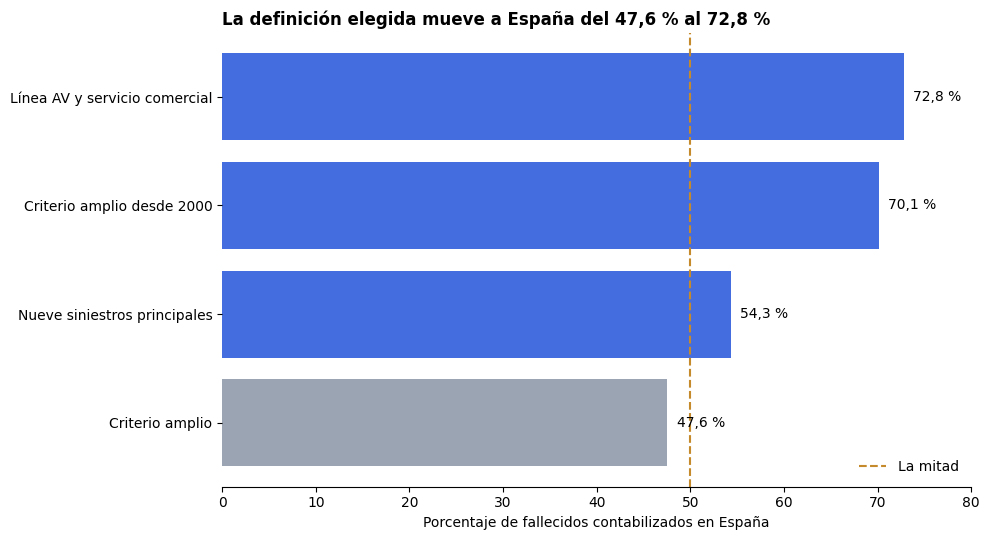

In [4]:
# dibujo el hallazgo central y marco la frontera de la mitad
orden = resumen.sort_values('porcentaje_españa')
fig, ax = plt.subplots(figsize=(10, 5.5))
colores = ['#9aa4b2' if valor < 50 else color_principal for valor in orden['porcentaje_españa']]
barras = ax.barh(orden['criterio'], orden['porcentaje_españa'], color=colores)
ax.axvline(50, color='#c58a2b', linestyle='--', linewidth=1.5, label='La mitad')
ax.set_xlim(0, 80)
ax.set_xlabel('Porcentaje de fallecidos contabilizados en España')
ax.set_title('La definición elegida mueve a España del 47,6 % al 72,8 %', loc='left', weight='bold')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.legend(frameon=False, loc='lower right')
for barra, valor in zip(barras, orden['porcentaje_españa']):
    ax.text(valor + 1, barra.get_y() + barra.get_height() / 2, f'{valor:.1f} %'.replace('.', ','), va='center')
plt.tight_layout()
plt.show()

El gráfico no permite elegir el criterio correcto por nosotros. Sí impide presentar uno de esos porcentajes como si fuese la única cuenta posible.

## El caso que más cambia la conversación

Angrois implicó un tren capaz de circular a 250 km/h y la Agencia Ferroviaria Europea lo describió como tren de alta velocidad. Sin embargo, el descarrilamiento sucedió al final del tramo de altas prestaciones, en una curva limitada a 80 km/h. Por eso algunas listas lo incluyen y otras no.

Repito el criterio amplio retirando únicamente Angrois. No afirmo que deba excluirse: mido cuánto pesa esa decisión.


In [5]:
# retiro solo Angrois para medir la sensibilidad a esa clasificación discutida
sin_angrois = datos.loc[~datos['lugar'].str.startswith('Angrois')]
total_sin_angrois = int(sin_angrois['fallecidos'].sum())
españa_sin_angrois = int(sin_angrois.loc[sin_angrois['pais'].eq('España'), 'fallecidos'].sum())
porcentaje_sin_angrois = españa_sin_angrois / total_sin_angrois * 100
{
    'fallecidos_en_españa': españa_sin_angrois,
    'fallecidos_en_el_mundo': total_sin_angrois,
    'porcentaje_españa': round(porcentaje_sin_angrois, 1),
}

{'fallecidos_en_españa': 115,
 'fallecidos_en_el_mundo': 330,
 'porcentaje_españa': 34.8}

Sin Angrois, España pasa de 195 a 115 fallecidos y su peso en el criterio amplio baja al **34,8 %**. Una sola decisión metodológica mueve casi trece puntos el resultado.

## Los accidentes grandes dominan el total

La comparación no describe una frecuencia estable ni el riesgo de cada viaje. Unos pocos sucesos extraordinariamente graves concentran casi toda la mortalidad. Lo compruebo ordenando los accidentes por número de fallecidos.


In [6]:
# calculo cuánto concentran los cinco accidentes con más fallecidos
orden_accidentes = datos.sort_values('fallecidos', ascending=False).copy()
orden_accidentes['porcentaje_acumulado'] = orden_accidentes['fallecidos'].cumsum() / orden_accidentes['fallecidos'].sum() * 100
orden_accidentes[['lugar', 'pais', 'fallecidos', 'porcentaje_acumulado']].head(8).round(1)

,lugar,pais,fallecidos,porcentaje_acumulado
0,Eschede,Alemania,101,24.6
1,Angrois (Santiago de Compostela),España,80,44.1
2,Urda (Toledo),España,69,61.0
3,Adamuz (Córdoba),España,46,72.2
4,Wenzhou,China,40,82.0
5,Ladbroke Grove,Reino Unido,31,89.5
6,Eckwersheim,Francia,11,92.2
7,Great Heck / Selby,Reino Unido,10,94.6


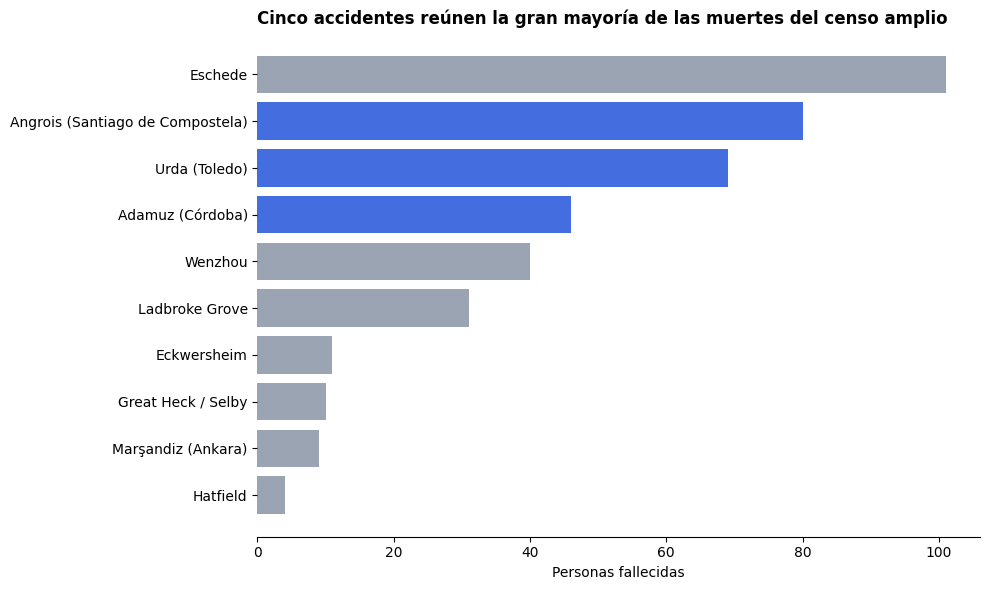

np.float64(82.0)

In [7]:
# muestro la concentración sin convertir el gráfico en un ranking de países
fig, ax = plt.subplots(figsize=(10, 6))
vista = orden_accidentes.head(10).sort_values('fallecidos')
colores = [color_principal if pais == 'España' else '#9aa4b2' for pais in vista['pais']]
ax.barh(vista['lugar'], vista['fallecidos'], color=colores)
ax.set_xlabel('Personas fallecidas')
ax.set_title('Cinco accidentes reúnen la gran mayoría de las muertes del censo amplio', loc='left', weight='bold')
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.tight_layout()
plt.show()

concentracion_cinco = orden_accidentes.head(5)['fallecidos'].sum() / orden_accidentes['fallecidos'].sum() * 100
round(concentracion_cinco, 1)

Los cinco accidentes más mortales reúnen el **89,3 %** del total amplio. Esto explica por qué un porcentaje por país puede saltar tanto tras uno o dos siniestros y por qué no debe confundirse con una tasa de seguridad.

## Limitaciones y explicaciones alternativas

- No hay un registro mundial único de accidentes de alta velocidad.
- El criterio amplio procede de una reconstrucción periodística y puede omitir casos.
- Algunas fuentes cuentan a pasajeros, personal ferroviario, ocupantes de vehículos o autores de incendios provocados dentro del mismo balance.
- No reúno heridos porque no existe una cifra homogénea para todos los casos. Por tanto, compruebo «fallecidos», no «víctimas» en sentido amplio.
- Los accidentes de Adamuz y Urda siguen bajo investigación y sus balances o clasificaciones pueden cambiar.
- Los totales absolutos no consideran kilómetros recorridos ni viajeros-kilómetro. No permiten afirmar que viajar en España sea más peligroso que hacerlo en otro país.
- Japón, por ejemplo, no registra muertes de pasajeros por colisión o descarrilamiento del Shinkansen desde 1964, pero esta tabla incluye un incendio provocado dentro de un tren. Esa diferencia muestra la importancia del criterio.

## Conclusión

La frase «España concentra más de la mitad» **no es una verdad estable sin letra pequeña**. Con el criterio amplio usado por Verificat, España representa el 47,6 % y queda por debajo. Con la selección de nueve siniestros principales alcanza el 54,3 %. Al limitar el periodo desde 2000 llega al 70,1 %, y con el criterio estricto de líneas de alta velocidad en servicio comercial alcanza el 72,8 %.

La conclusión más robusta no es un porcentaje único: España soporta una parte extraordinariamente alta de las muertes contabilizadas, pero la frontera entre «alta velocidad» y «tren rápido en una línea convencional» decide si la afirmación supera o no la mitad. Para evaluar seguridad harían falta tasas comparables por viajeros-kilómetro, no solo una suma histórica de tragedias.
